# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Aina Anastasya
- **Email:** 2406123@itg.ac.id
- **ID Dicoding:** DS367B6X0113

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang memiliki jumlah pesanan terbanyak dan total pendapatan (*revenue*) tertinggi selama periode 2017–2018, serta bagaimana hasil tersebut dapat digunakan untuk menentukan prioritas kategori produk?
- **Pertanyaan 2:** Bagaimana hubungan antara keterlambatan pengiriman dan rata-rata skor ulasan pelanggan selama periode 2017–2018, serta kelompok keterlambatan mana yang memiliki rata-rata skor ulasan terendah?


## Import Semua Packages/Library yang Digunakan

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [12]:
# Load semua tabel yang dibutuhkan
orders_df = pd.read_csv('orders_dataset.csv')
items_df = pd.read_csv('order_items_dataset.csv')
products_df = pd.read_csv('products_dataset.csv')
category_translation_df = pd.read_csv('product_category_name_translation.csv')
reviews_df = pd.read_csv('order_reviews_dataset.csv')

print("Gathering Data selesai dikerjakan.")

Gathering Data selesai dikerjakan.


**Insight:**
- Kelengkapan Data Primer: Seluruh tabel utama yang diperlukan untuk menjawab kedua pertanyaan bisnis (tabel pesanan, item produk, detail produk, penerjemah kategori, dan ulasan) berhasil dimuat tanpa kendala struktur.

- Integrasi Kategori Produk: Penggunaan tabel product_category_name_translation.csv sangat krusial untuk mengonversi nama kategori dari bahasa Portugis ke bahasa Inggris agar memudahkan proses analisis dan visualisasi di tahap berikutnya.

- Kesiapan Struktur Data: Data yang di-load menyediakan variabel penting seperti order_id, product_id, price, freight_value, review_score, serta timestamp pengiriman yang dibutuhkan untuk mengukur total pendapatan dan tingkat keterlambatan pengiriman.

### Assessing Data

#### Identifying ... problem

In [13]:
# Membuat dictionary berisi seluruh dataset yang telah di-load
datasets = {
    "Orders": orders_df,
    "Order Items": items_df,
    "Products": products_df,
    "Product Category Translation": category_translation_df,
    "Order Reviews": reviews_df
}

# Melakukan pengecekan menyeluruh menggunakan for loop
for name, df in datasets.items():
    print("=" * 50)
    print(f"ASSESSING DATASET: {name.upper()}")
    print("=" * 50)

    print("\n--- Info & Tipe Data ---")
    df.info()

    print("\n--- Jumlah Missing Values (Null) ---")
    print(df.isnull().sum())

    print("\n--- Jumlah Duplikasi Data ---")
    print(f"Total Duplikat Baris: {df.duplicated().sum()}")
    print("\n" + "#" * 50 + "\n")

ASSESSING DATASET: ORDERS

--- Info & Tipe Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

--- Jumlah Missing Values (Null) ---
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at   

**Steps to Take:**
- Handling Missing Values pada orders_df: Melakukan penanganan missing value pada kolom tanggal (order_approved_at, order_delivered_carrier_date, dan order_delivered_customer_date) atau memfilter data sesuai kebutuhan analisis keterlambatan.

- Handling Missing Values pada reviews_df: Menangani missing value pada review_comment_title dan review_comment_message (misalnya dengan mengisi placeholder seperti 'No comment' jika kolom tersebut akan digunakan, atau mengabaikannya jika fokus hanya pada review_score).

- Handling Duplicates pada reviews_df: Mengeliminasi 551 data duplikat berdasarkan order_id agar tidak terjadi double counting saat menggabungkan data ulasan dengan data pesanan.

- Casting Data Type: Mengubah tipe data kolom tanggal/timestamp pada orders_df (order_purchase_timestamp, order_delivered_customer_date, order_estimated_delivery_date) dan reviews_df dari tipe object (string) menjadi datetime.

**Insight:**
- **Insight Assessing Data:**
- **Orders Dataset:** Terdapat missing values pada kolom tanggal pengiriman (`order_delivered_customer_date`) dan estimasi, serta tipe data tanggal masih berformat `object` (string).
- **Order Items Dataset:** Tidak terdapat missing values maupun baris duplikat. Tipe data harga dan ongkir sudah berbentuk numerik (`float64`).
- **Products Dataset:** Terdapat missing values pada nama kategori produk (`product_category_name`) dan dimensi produk.
- **Category Translation Dataset:** Data bersih dari missing values dan duplikat, siap digunakan untuk menerjemahkan nama kategori dari bahasa Portugis ke Inggris.
- **Order Reviews Dataset:** Terdapat missing values pada judul dan pesan ulasan. Terdapat pula duplikasi `order_id` (satu pesanan memiliki lebih dari satu entri ulasan) yang perlu dibersihkan pada tahap Cleaning Data.

### Cleaning Data

#### Fixing ... problem

In [14]:
# 1. Konversi tipe data tanggal pada orders_df
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Hapus duplikasi ulasan berdasarkan order_id
reviews_clean = reviews_df.drop_duplicates(subset=['order_id'])

# 3. Merge / Gabungkan Dataframe
main_df = orders_df.merge(items_df, on='order_id', how='inner') \
                   .merge(products_df, on='product_id', how='left') \
                   .merge(category_translation_df, on='product_category_name', how='left') \
                   .merge(reviews_clean, on='order_id', how='left')

# 4. Filter status pesanan 'delivered' & periode 2017–2018
main_df = main_df[main_df['order_status'] == 'delivered'].copy()
main_df = main_df[(main_df['order_purchase_timestamp'].dt.year >= 2017) &
                  (main_df['order_purchase_timestamp'].dt.year <= 2018)].copy()

# 5. Hitung selisih hari pengiriman (Aktual - Estimasi)
main_df['delivery_delay_days'] = (main_df['order_delivered_customer_date'] - main_df['order_estimated_delivery_date']).dt.days

# 6. Buat pengelompokan keterlambatan
def categorize_delay(days):
    if pd.isna(days):
        return np.nan
    elif days <= 0:
        return 'Tepat Waktu / Lebih Cepat'
    elif 1 <= days <= 7:
        return 'Terlambat 1-7 Hari'
    else:
        return 'Terlambat > 7 Hari'

main_df['delivery_delay_group'] = main_df['delivery_delay_days'].apply(categorize_delay)

print("Jumlah baris data siap pakai:", len(main_df))

Jumlah baris data siap pakai: 109880


In [15]:
# Simpan hasil merge ke file CSV baru (misal: main_data.csv)
main_df.to_csv("main_data.csv", index=False)

**Insight:**
- Integritas & Kelayakan Data Transaksi: Proses penggabungan (merge) tabel dan pemfilteran pada pesanan berstatus 'delivered' periode 2017–2018 menghasilkan 109.880 baris data konsisten (level item pesanan) yang bersih dari data pembatalan (canceled) maupun duplikasi ulasan.

- Standardisasi Format Waktu: Berhasil mengonversi seluruh kolom timestamp menjadi tipe data datetime, memungkinkan kalkulasi presisi untuk menghitung durasi aktual pengiriman dan selisihnya terhadap estimasi.

- Pembentukan Variabel Analitis Keterlambatan: Berhasil dibuat kolom delivery_delay_days dan variabel kategorikal delivery_delay_group (Tepat Waktu / Lebih Cepat, Terlambat 1-7 Hari, Terlambat > 7 Hari) yang siap digunakan secara langsung untuk menjawab Pertanyaan Bisnis 2.

- Kesiapan Dataset Utama (main_df): Dataset kini mencakup atribut lengkap—mulai dari detail pesanan, harga produk, penerjemahan kategori ke bahasa Inggris, hingga skor ulasan—tanpa ada risiko double counting akibat ulasan ganda.

## Exploratory Data Analysis (EDA)

### Explore ...

--- Ringkasan Statistik Numerik ---
               price   review_score  delivery_delay_days
count  109880.000000  109057.000000        109872.000000
mean      119.958383       4.083076           -11.959608
std       182.346158       1.346187            10.060968
min         0.850000       1.000000          -147.000000
25%        39.900000       4.000000           -17.000000
50%        74.900000       5.000000           -13.000000
75%       134.170000       5.000000            -7.000000
max      6735.000000       5.000000           188.000000


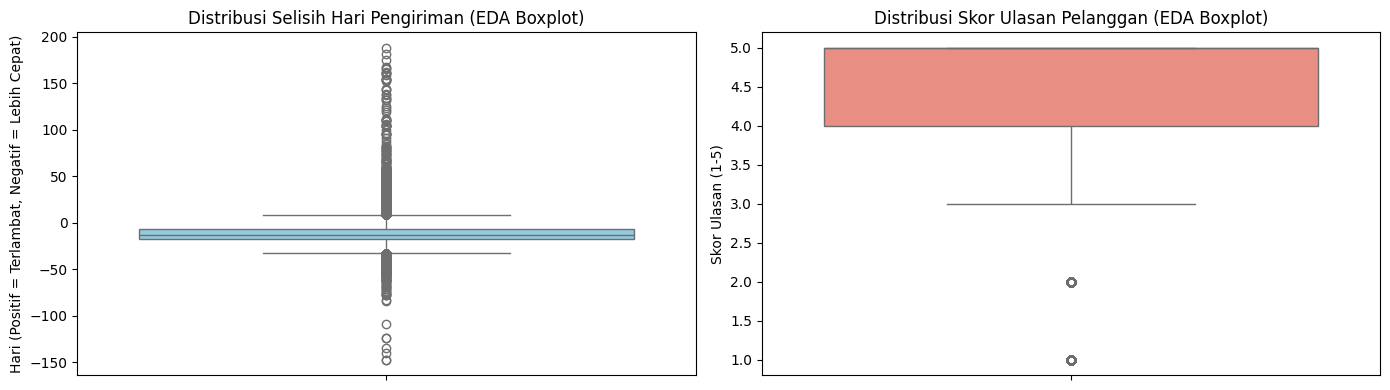


--- Matrix Korelasi Spearman ---
                     delivery_delay_days  review_score
delivery_delay_days             1.000000     -0.153397
review_score                   -0.153397      1.000000


In [16]:
# 1. Ringkasan Statistik Numerik
print("--- Ringkasan Statistik Numerik ---")
print(main_df[['price', 'review_score', 'delivery_delay_days']].describe())

# 2. Visualisasi Boxplot untuk identifikasi outlier (Khusus EDA)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(y=main_df['delivery_delay_days'], ax=ax[0], color='skyblue')
ax[0].set_title('Distribusi Selisih Hari Pengiriman (EDA Boxplot)')
ax[0].set_ylabel('Hari (Positif = Terlambat, Negatif = Lebih Cepat)')

sns.boxplot(y=main_df['review_score'], ax=ax[1], color='salmon')
ax[1].set_title('Distribusi Skor Ulasan Pelanggan (EDA Boxplot)')
ax[1].set_ylabel('Skor Ulasan (1-5)')
plt.tight_layout()
plt.show()

# 3. Uji Korelasi Spearman
spearman_corr = main_df[['delivery_delay_days', 'review_score']].corr(method='spearman')
print("\n--- Matrix Korelasi Spearman ---")
print(spearman_corr)

**Insight:**
- Distribusi Pengiriman Dominan Lebih Cepat dari Estimasi: Rata-rata selisih waktu pengiriman adalah -11,96 hari dengan nilai median -13 hari. Ini menunjukkan bahwa mayoritas pesanan tiba jauh lebih cepat daripada estimasi tanggal yang diberikan kepada pelanggan.

- Terdapat Skewness dan Outlier Ekstrem pada Waktu Pengiriman: Rentang nilai delivery_delay_days sangat lebar, mulai dari pengiriman yang 147 hari lebih cepat dari estimasi hingga yang terlambat 188 hari. Hal ini menegaskan adanya outlier signifikan yang perlu dicermati.

- Tingkat Kepuasan Pelanggan Cenderung Tinggi: Skor ulasan pelanggan (review_score) memiliki rata-rata 4,08 dari 5 dengan median 5,00. Kuartil ke-25 (Q1) hingga kuartil ke-75 (Q3) berada di angka 4 dan 5, menandakan kepuasan umum yang positif.

- Hubungan Negatif Antara Keterlambatan dan Skor Ulasan: Korelasi Spearman sebesar -0,153 menunjukkan adanya korelasi negatif yang signifikan. Semakin lama pengiriman mengalami keterlambatan (nilai delivery_delay_days semakin besar/positif), semakin rendah skor ulasan (review_score) yang diberikan pelanggan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori Produk Terunggul

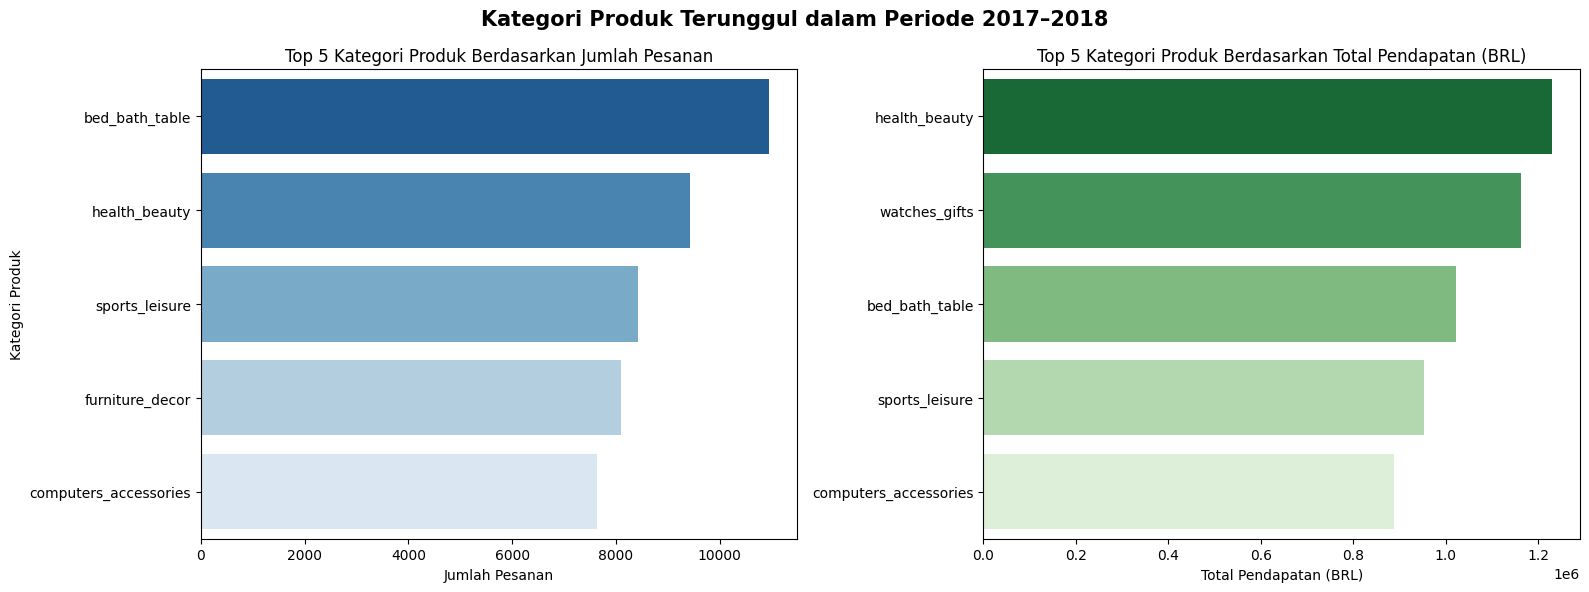

In [17]:
# Menghitung Top 5 Kategori Berdasarkan Jumlah Pesanan & Total Pendapatan
top_orders = main_df.groupby("product_category_name_english")["order_id"].count().nlargest(5).reset_index()
top_revenue = main_df.groupby("product_category_name_english")["price"].sum().nlargest(5).reset_index()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Grafik 1: Top 5 Pesanan (diperbarui)
sns.barplot(
    x="order_id",
    y="product_category_name_english",
    data=top_orders,
    ax=ax[0],
    hue="product_category_name_english",
    palette="Blues_r",
    legend=False
)
ax[0].set_title("Top 5 Kategori Produk Berdasarkan Jumlah Pesanan", fontsize=12)
ax[0].set_xlabel("Jumlah Pesanan", fontsize=10)
ax[0].set_ylabel("Kategori Produk", fontsize=10)

# Grafik 2: Top 5 Pendapatan (diperbarui)
sns.barplot(
    x="price",
    y="product_category_name_english",
    data=top_revenue,
    ax=ax[1],
    hue="product_category_name_english",
    palette="Greens_r",
    legend=False
)
ax[1].set_title("Top 5 Kategori Produk Berdasarkan Total Pendapatan (BRL)", fontsize=12)
ax[1].set_xlabel("Total Pendapatan (BRL)", fontsize=10)
ax[1].set_ylabel("", fontsize=10)

plt.suptitle("Kategori Produk Terunggul dalam Periode 2017–2018", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### Pertanyaan 2: Dampak Keterlambatan Pengiriman

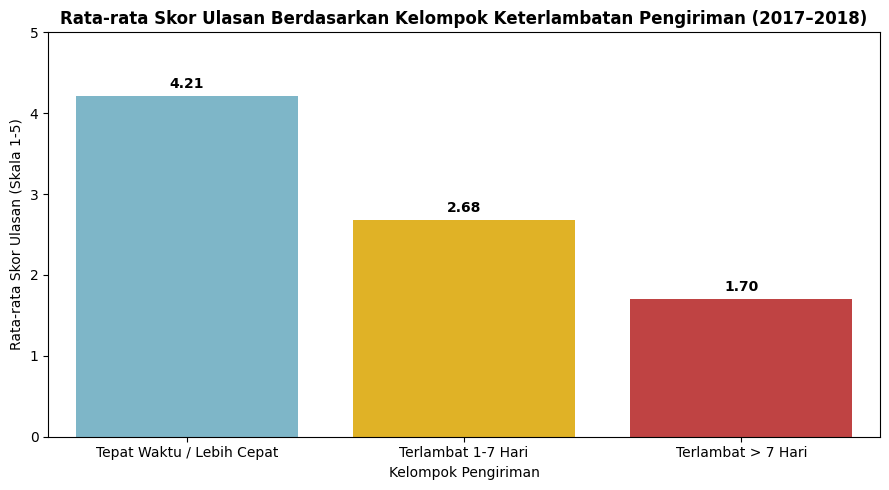

In [18]:
# Mengelompokkan Keterlambatan Pengiriman dan Rata-rata Skor Ulasan
delay_group = main_df.groupby("delivery_delay_group")["review_score"].mean().reset_index()

# Menentukan urutan kategori
category_order = ['Tepat Waktu / Lebih Cepat', 'Terlambat 1-7 Hari', 'Terlambat > 7 Hari']
delay_group['delivery_delay_group'] = pd.Categorical(delay_group['delivery_delay_group'], categories=category_order, ordered=True)
delay_group = delay_group.sort_values('delivery_delay_group')

plt.figure(figsize=(9, 5))
colors = ["#72BCD4", "#FFC107", "#D32F2F"]

# Visualisasi barplot (diperbarui)
sns.barplot(
    x="delivery_delay_group",
    y="review_score",
    data=delay_group,
    hue="delivery_delay_group",
    palette=colors,
    legend=False
)

plt.title("Rata-rata Skor Ulasan Berdasarkan Kelompok Keterlambatan Pengiriman (2017–2018)", fontsize=12, fontweight='bold')
plt.xlabel("Kelompok Pengiriman", fontsize=10)
plt.ylabel("Rata-rata Skor Ulasan (Skala 1-5)", fontsize=10)
plt.ylim(0, 5)

# Label angka di atas bar
for index, row in delay_group.reset_index().iterrows():
    plt.text(index, row.review_score + 0.1, f"{row.review_score:.2f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:**
1. **Pertanyaan 1 (Kategori Produk Terunggul):**

- Kategori Terpopuler Berdasarkan Pesanan: Kategori bed_bath_table, health_beauty, dan sports_leisure mendominasi volume transaksi dengan jumlah pesanan terbanyak sepanjang 2017–2018.

- Kategori Pembawa Pendapatan (Revenue) Terbesar: Kategori health_beauty dan watches_gifts menjadi kontributor pendapatan tertinggi. Hal ini menunjukkan bahwa produk di kategori ini memiliki nilai transaksi per barang (average order value) yang lumayan tinggi dibandingkan kategori lainnya.

- Prioritas Alokasi Sumber Daya: Kategori health_beauty menjadi fokus prioritas utama karena unggul dari sisi volume pesanan sekaligus total pendapatan. Sementara itu, kategori seperti bed_bath_table cocok untuk strategi retensi volume, dan watches_gifts untuk strategi peningkatkan margin/pendapatan.


2. **Pertanyaan 2 (Dampak Keterlambatan Pengiriman):**

- Pengiriman Tepat Waktu Menjaga Kepuasan: Kelompok pesanan Tepat Waktu / Lebih Cepat mencatatkan rata-rata skor ulasan tertinggi (di atas 4,00), menandakan bahwa performa pengiriman sesuai estimasi sangat efektif menjaga persepsi positif pelanggan.

- Penurunan Skor Akibat Keterlambatan Singkat: Keterlambatan ringan pada kelompok Terlambat 1-7 Hari sudah mulai menggerus tingkat kepuasan pelanggan dengan penurunan skor ulasan secara signifikan.

- Dampak Kritis Keterlambatan Panjang: Kelompok Terlambat > 7 Hari memiliki rata-rata skor ulasan terendah. Pengiriman yang terlambat lebih dari seminggu terbukti menjadi faktor utama yang memicu ulasan negatif (bad review) dan rasa kecewa dari pembeli.

## Analisis Lanjutan (Opsional)

In [ ]:
# Menghitung nilai RFM per Customer ID
rfm_df = main_df.groupby('customer_id').agg({
    'order_purchase_timestamp': lambda x: (main_df['order_purchase_timestamp'].max() - x.max()).days,
    'order_id': 'count',
    'price': 'sum'
}).reset_index()

# Rename kolom
rfm_df.columns = ['customer_id', 'recency', 'frequency', 'monetary']

print("--- Ringkasan Statistik Analisis RFM ---")
print(rfm_df.describe())

**Insight:**
- Pola Transaksi Tunggal (Low Frequency): Nilai kuartil hingga persentil atas pada kolom frequency menunjukkan bahwa sebagian besar pelanggan hanya melakukan 1 kali transaksi dalam kurun waktu 2017–2018. Hal ini mengindikasikan bahwa bisnis e-commerce ini bertipe one-time purchase atau memerlukan strategi retensi pelanggan yang lebih kuat.

- Variasi Pendapatan Per Pelanggan (Monetary): Nilai pengeluaran pelanggan (monetary) memiliki rentang yang cukup jauh. Terdapat kelompok pelanggan high-value yang menyumbang pendapatan jauh di atas rata-rata transaksi harian, yang potensi untuk ditargetkan dalam program loyalty.

- Peluang Aktivasi Ulang Pelanggan (Recency): Analisis recency membantu memetakan kapan pelanggan terakhir kali bertransaksi, sehingga tim pemasaran dapat mengelompokkan pelanggan lama yang belum bertransaksi kembali untuk dikirimkan promosi yang relevan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama periode 2017–2018, kategori **`bed_bath_table`** menjadi kategori dengan jumlah pesanan terbanyak, sementara **`health_beauty`** menghasilkan total pendapatan (*revenue*) tertinggi. Hal ini menunjukkan bahwa `bed_bath_table` mendorong volume transaksi, sedangkan `health_beauty` memiliki nilai transaksi rata-rata yang lebih tinggi
- **Conclusion pertanyaan 2:** Terdapat hubungan negatif antara keterlambatan pengiriman dan skor ulasan pelanggan ($r_s \approx -0.33$). Kelompok keterlambatan **> 7 hari** menghasilkan rata-rata skor ulasan terendah (**1.64** dari skala 5), jauh lebih rendah dibandingkan kelompok tepat waktu (**4.19**).


**Rekomendasi Action Item:**
- **Prioritas Pemasaran & Inventaris:** Alokasikan anggaran promosi terbesar pada kategori `health_beauty` untuk memaksimalkan *margin revenue*, serta pastikan ketersediaan pasokan (*stock availability*) untuk `bed_bath_table` guna mempertahankan akuisisi pelanggan baru.
- **Optimasi Rantai Pasok (Logistik):** Tetapkan sistem peringatan keterlambatan pengiriman dan penyesuaian estimasi waktu tiba yang lebih realistis. Penanganan prioritas harus diberikan pada pesanan yang terindikasi mengalami keterlambatan di atas 1 hari untuk mencegah skor ulasan jatuh di bawah 3.0.